**9.2　Prophetによる日経平均株価の予測**

以下では、Prophetを用いた株価の予測例を紹介します。ライブラリは、まず数値計算用のpandas、データ取得を目的とするpandas datareader、標本期間を指定するためのdatetime、時系列モデルにベイズ統計を用いるためのstan、そして時系列モデル用のprophet、最後に図表用のライブラリであるmatplotlibを読み込みます。Prophetではベイズ統計を用いることで、新たな情報（データ）が加わる度に、予測時の確率分布を変化させます。

In [1]:
#[1]ライブラリ読み込み
import pandas as pd
import pandas_datareader as data
import datetime
from prophet import Prophet #時系列モデル用ライブラリ
import matplotlib.pyplot as plt
import yfinance as yf

続いて日経平均株価のヒストリカル・データを取得します。

In [ ]:
#[2]データ取得
tickers=['^N225']
nikkei = yf.download(tickers, start='2000-1-1', end='2026-10-30')
nikkei = nikkei['Close']
nikkei.head()

Prophetでは変数名を日時＝'ds'、予測する変数＝'y'に指定されています。このため一度、データフレームのインデックス名を一度リセットして日時をdsへ、予測したい変数をｙへ変数名を変更します。

In [5]:
#[3]データフレームの整理
nikkei.reset_index(inplace=True) #prophetの変数定義への変更するためリセット
nikkei = nikkei.rename(columns={'Date': 'ds','^N225': 'y'}) #prophetの変数定義への変更

最後のセルでは、一行目で時系列モデルにProphetを使用する指示を与えます。二行目においてヒストリカル・データをフィッティングし、三行目で予測期間を指定します。これらを実施した後、予測結果を保存し、可視化します。

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


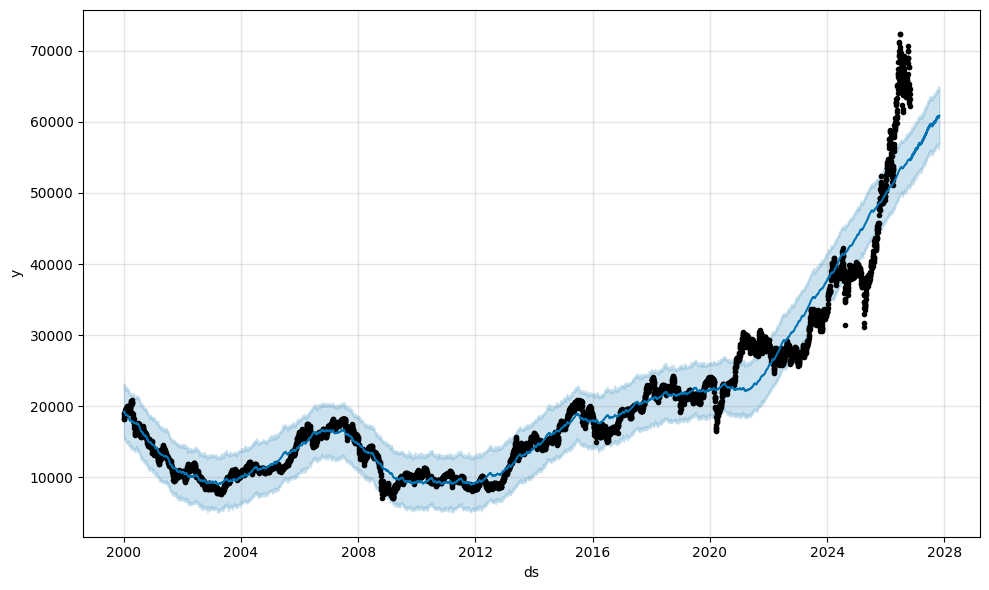

In [6]:
#[4]2027年10月30日の日経平均株価の予測
model = Prophet() #時系列モデルにprophetを採用：モデル名をmodel
model.fit(nikkei) #データを時系列モデルにフィッティング
future = model.make_future_dataframe(periods=365,freq="d") #予測の期間と頻度の定義
forecast = model.predict(future)#予測結果の保存
model.plot(forecast)#可視化
plt.show()

尚、予測結果の各データは下記により取得、保存できます。

In [ ]:
#[5]予測結果のデータ確認
pd.set_option("display.max_rows", len(forecast))
forecast